## **Health and Lifestyle Data for Regression**

#### El conjunto de datos Health and Lifestyle Data for Regression, disponible públicamente en Kaggle, contiene información sobre los hábitos de vida y el estado de salud de diferentes individuos. Su propósito original es analizar cómo los factores de estilo de vida (como la dieta, el ejercicio o el sueño) afectan indicadores de bienestar físico y mental.

#### El dataset incluye observaciones completamente numéricas, lo que lo hace ideal para técnicas de aprendizaje no supervisado como PCA y K-Means.

### Variables incluidas

| Variable | Descripción | Tipo |
|-----------|--------------|------|
| **Age** | Edad del individuo (en años). | Numérica |
| **BMI** | Índice de Masa Corporal (kg/m²). | Numérica |
| **Exercise_Frequency** | Frecuencia de ejercicio semanal (días/semana). | Numérica |
| **Sleep_Hours** | Promedio de horas de sueño por día. | Numérica |
| **Water_Intake** | Consumo promedio de agua (litros por día). | Numérica |
| **Calorie_Intake** | Ingesta calórica promedio diaria. | Numérica |
| **Screen_Time** | Tiempo frente a pantallas (horas por día). | Numérica |
| **Stress_Level** | Nivel de estrés percibido (escala 1–10). | Numérica |
| **Physical_Health** | Índice de salud física (escala 1–100). | Numérica |
| **Mental_Health** | Índice de salud mental (escala 1–100). | Numérica |

In [1]:
# ==========================
# Importar librerías
# ==========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import RandomForestRegressor

In [4]:
# ==========================
# Cargar el dataset
# ==========================

df = pd.read_csv("synthetic_health_data.csv")

# Verificar estructura
print("Dimensiones:", df.shape)
print("Columnas:\n", df.columns)
print("\nValores nulos:\n", df.isnull().sum())

Dimensiones: (1000, 8)
Columnas:
 Index(['Age', 'BMI', 'Exercise_Frequency', 'Diet_Quality', 'Sleep_Hours',
       'Smoking_Status', 'Alcohol_Consumption', 'Health_Score'],
      dtype='object')

Valores nulos:
 Age                    0
BMI                    0
Exercise_Frequency     0
Diet_Quality           0
Sleep_Hours            0
Smoking_Status         0
Alcohol_Consumption    0
Health_Score           0
dtype: int64


In [7]:
print("\nInformación general:")
print(df.info())


Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  1000 non-null   float64
 1   BMI                  1000 non-null   float64
 2   Exercise_Frequency   1000 non-null   int64  
 3   Diet_Quality         1000 non-null   float64
 4   Sleep_Hours          1000 non-null   float64
 5   Smoking_Status       1000 non-null   int64  
 6   Alcohol_Consumption  1000 non-null   float64
 7   Health_Score         1000 non-null   float64
dtypes: float64(6), int64(2)
memory usage: 62.6 KB
None


In [11]:
# ==========================
# Seleccionar variables numéricas
# ==========================
# Usamos las variables que sí existen en el dataset
variables = [
    'Age', 'BMI', 'Exercise_Frequency', 'Diet_Quality',
    'Sleep_Hours', 'Smoking_Status', 'Alcohol_Consumption', 'Health_Score'
]

df = df[variables]

print("Dimensiones después de seleccionar variables:", df.shape)
print("Primeras filas del dataset:")
display(df.head())

Dimensiones después de seleccionar variables: (1000, 8)
Primeras filas del dataset:


,Age,BMI,Exercise_Frequency,Diet_Quality,Sleep_Hours,Smoking_Status,Alcohol_Consumption,Health_Score
0,45.960570,31.996777,5,55.403270,7.300359,0,2.834707,70.542122
1,38.340828,29.623168,6,41.838357,7.012419,1,7.199517,57.244637
2,47.772262,25.298152,5,76.904948,6.028641,1,4.097944,96.333722
3,58.276358,21.765316,2,49.756767,5.802714,1,3.649377,61.321783
4,37.190160,28.491117,2,44.218737,7.912548,0,2.839795,67.175894


In [12]:
# ==========================
# Estandarizar los datos
# ==========================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

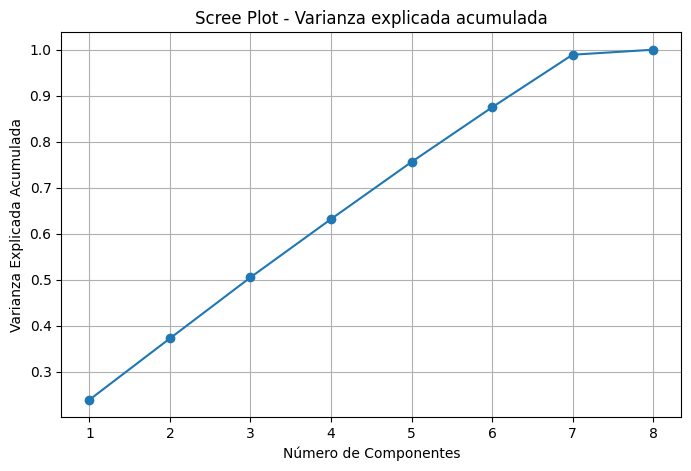

In [14]:
# ==========================
# Aplicar PCA
# ==========================

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Varianza explicada
explained_var = pca.explained_variance_ratio_

# Scree plot
plt.figure(figsize=(8,5))
plt.plot(range(1, len(explained_var)+1), explained_var.cumsum(), marker='o')
plt.title('Scree Plot - Varianza explicada acumulada')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada')
plt.grid(True)
plt.show()

##### El gráfico Scree Plot muestra la varianza explicada acumulada por los componentes principales del análisis PCA. Se observa que los primeros 6 componentes explican cerca del 90% de la varianza total, lo que indica que gran parte de la información contenida en las variables originales puede resumirse adecuadamente con ellos. A partir del séptimo componente, la ganancia adicional de varianza es mínima, por lo que mantener más componentes no aporta información relevante y solo incrementa la complejidad del modelo.

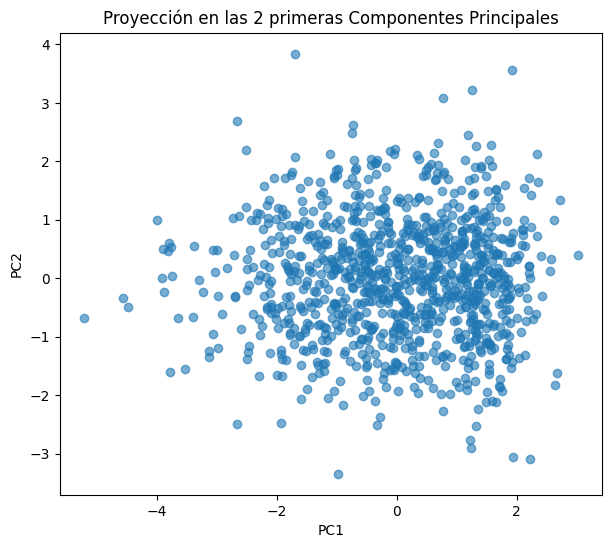

In [15]:
# ==========================
# Reducir a 2 componentes principales
# ==========================
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(7,6))
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], alpha=0.6)
plt.title("Proyección en las 2 primeras Componentes Principales")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

##### El gráfico muestra la proyección de los datos en las dos primeras Componentes Principales (PC1 y PC2) del análisis PCA. Cada punto representa una observación transformada según estas nuevas dimensiones que concentran la mayor parte de la varianza del conjunto de datos. Se observa que los puntos están distribuidos de manera relativamente homogénea y sin una clara separación de grupos, lo que sugiere que las variables originales están correlacionadas pero no forman clústeres naturales evidentes. En conjunto, PC1 y PC2 capturan una parte importante de la estructura subyacente de los datos, facilitando su visualización en dos dimensiones.

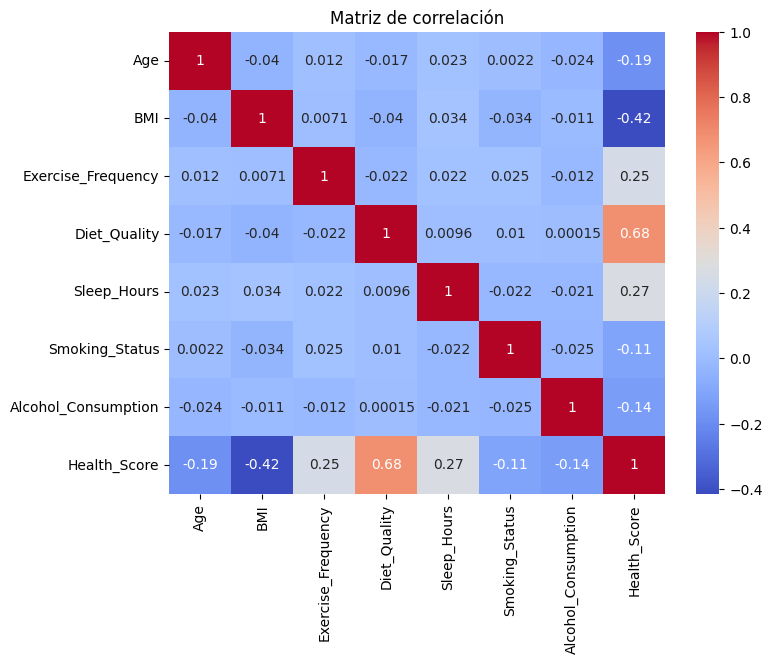

Variables eliminadas por correlación: set()
Variables restantes: ['Age', 'BMI', 'Exercise_Frequency', 'Diet_Quality', 'Sleep_Hours', 'Smoking_Status', 'Alcohol_Consumption', 'Health_Score']


In [19]:
# ==========================
# Selección de variables (correlación y árbol)
# ==========================
# --- (a) Análisis de correlación ---
corr = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

# Eliminamos variables altamente correlacionadas (corr > 0.85)
to_drop = set()
for i in range(len(corr.columns)):
    for j in range(i):
        if abs(corr.iloc[i, j]) > 0.85:
            to_drop.add(corr.columns[i])
            
df_reduced = df.drop(columns=to_drop)
print("Variables eliminadas por correlación:", to_drop)
print("Variables restantes:", df_reduced.columns.tolist())

##### La matriz de correlación muestra las relaciones lineales entre las variables del conjunto de datos. Se observa que la mayoría de las correlaciones son bajas, lo que indica que las variables son relativamente independientes entre sí. Sin embargo, destacan algunas asociaciones más fuertes, como la correlación positiva entre “Diet_Quality” y “Health_Score” (0.68), lo que sugiere que una mejor calidad de dieta se asocia con una mayor puntuación de salud. También hay una correlación negativa entre “BMI” y “Health_Score” (-0.42), indicando que un índice de masa corporal más alto tiende a relacionarse con una menor salud general. En conjunto, esta matriz permite identificar variables redundantes o altamente relacionadas que podrían eliminarse en el proceso de selección de características.


--- Importancia de características ---
Diet_Quality           0.518138
BMI                    0.197819
Sleep_Hours            0.101717
Exercise_Frequency     0.067462
Age                    0.061976
Alcohol_Consumption    0.043727
Smoking_Status         0.009162
dtype: float64


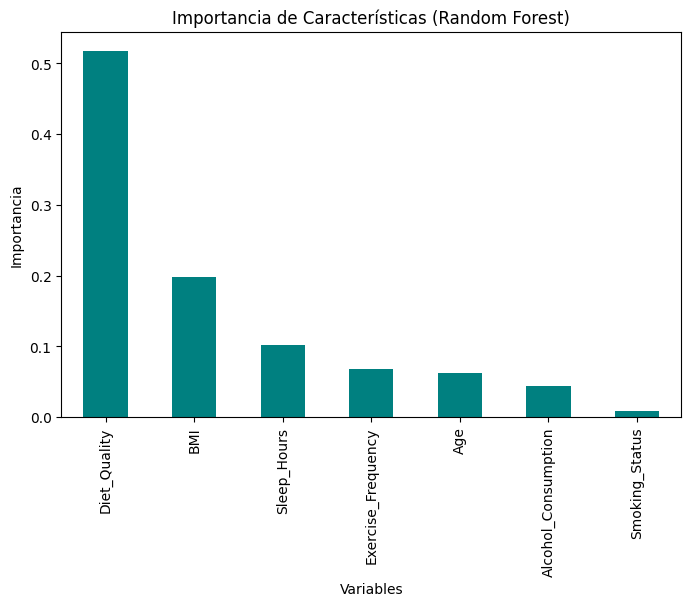

In [20]:
# --- (a) Separación de variables ---
X = df.drop(columns=['Health_Score'])
y = df['Health_Score']

# Escalamiento de las variables predictoras
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- (b) Importancia de características con RandomForest ---
rf = RandomForestRegressor(random_state=42)
rf.fit(X_scaled, y)  # Usamos Health_Score como variable objetivo

# Convertimos a Series para visualizar la importancia
importance = pd.Series(rf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)

print("\n--- Importancia de características ---")
print(importance)

# Gráfico de importancia
plt.figure(figsize=(8, 5))
importance.plot(kind='bar', color='teal')
plt.title('Importancia de Características (Random Forest)')
plt.xlabel('Variables')
plt.ylabel('Importancia')
plt.show()

##### El gráfico de importancia de características obtenido con el modelo Random Forest muestra cuáles variables contribuyen más a explicar la variación en el puntaje de salud (Health_Score). Se observa que “Diet_Quality” es, con diferencia, la variable más relevante, seguida por “BMI” y “Sleep_Hours”, mientras que “Smoking_Status” y “Alcohol_Consumption” tienen una influencia marginal. Esto sugiere que los factores relacionados con la alimentación, el peso corporal y el descanso son los que más impactan en la salud general, lo que resulta coherente desde una perspectiva médica y de bienestar.

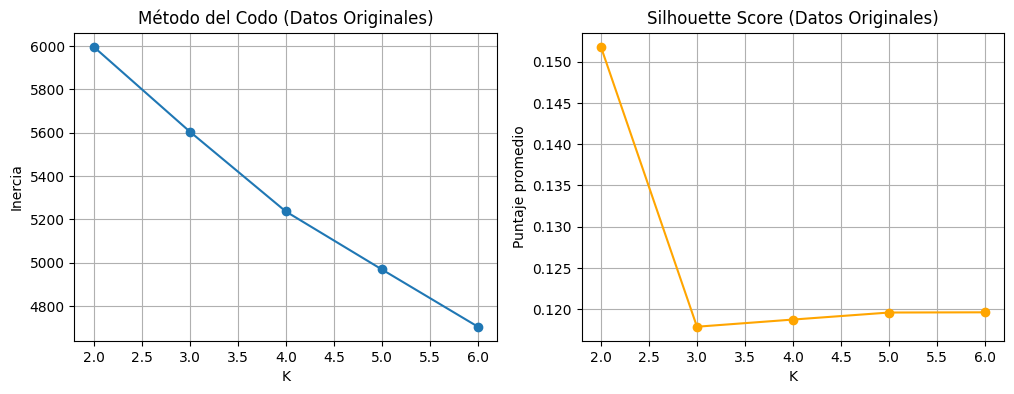

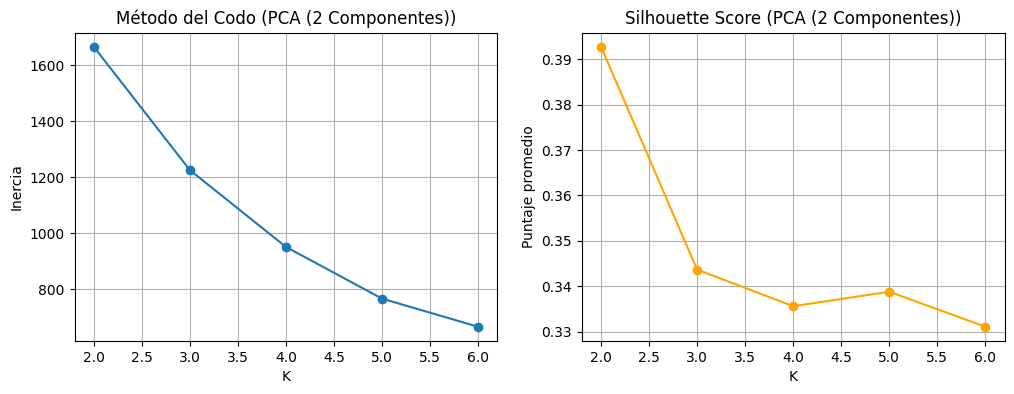

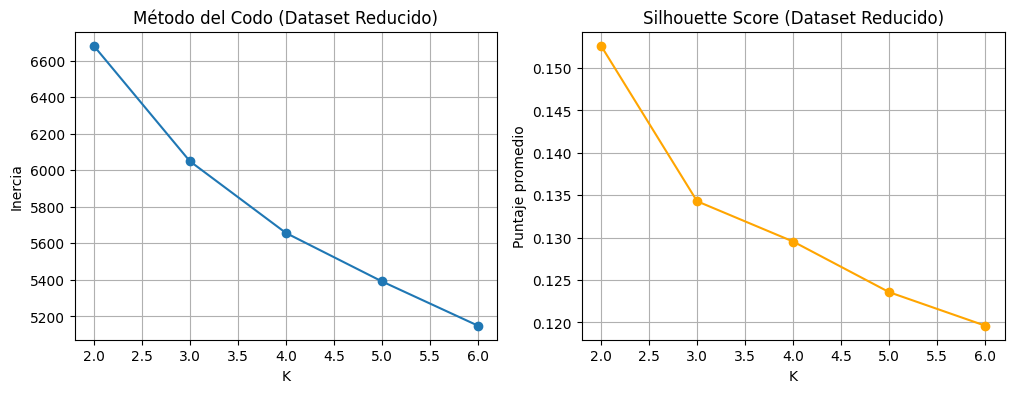

In [21]:
# ==========================
# K-means en tres versiones del dataset
# ==========================
def evaluar_kmeans(X, nombre):
    inertia = []
    sil_scores = []
    K_range = range(2, 7)
    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X)
        inertia.append(kmeans.inertia_)
        sil_scores.append(silhouette_score(X, labels))
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(K_range, inertia, marker='o')
    plt.title(f"Método del Codo ({nombre})")
    plt.xlabel("K")
    plt.ylabel("Inercia")
    plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(K_range, sil_scores, marker='o', color='orange')
    plt.title(f"Silhouette Score ({nombre})")
    plt.xlabel("K")
    plt.ylabel("Puntaje promedio")
    plt.grid(True)
    plt.show()

# (1) Original
evaluar_kmeans(X_scaled, "Datos Originales")

# (2) PCA (2 componentes)
evaluar_kmeans(X_pca_2, "PCA (2 Componentes)")

# (3) Dataset reducido
X_reduced_scaled = scaler.fit_transform(df_reduced)
evaluar_kmeans(X_reduced_scaled, "Dataset Reducido")


##### El gráfico 1 muestra los resultados del algoritmo K-means aplicado sobre los datos originales. En el método del codo (izquierda), la inercia disminuye a medida que aumenta el número de clústeres, pero se observa un cambio menos pronunciado a partir de K = 3 o 4, lo que sugiere que esa podría ser una elección razonable para el número de grupos. En el gráfico de la derecha, el Silhouette Score alcanza su valor máximo en K = 2, indicando que con dos clústeres los datos presentan la mayor coherencia interna. En conjunto, estos resultados sugieren que entre 2 y 3 clústeres representan una partición adecuada de los datos originales, aunque la estructura general no muestra una separación muy fuerte entre grupos.

##### En los resultados de K-means aplicados sobre los datos reducidos mediante PCA (2 componentes principales), el gráfico del método del codo (izquierda) muestra una caída pronunciada en la inercia hasta aproximadamente K = 3, después de lo cual las mejoras son menores. Esto indica que tres clústeres podrían ser una elección razonable. En el gráfico del Silhouette Score (derecha), el puntaje más alto se observa nuevamente en K = 2, sugiriendo que dos grupos producen la mejor separación en este espacio reducido. En general, la reducción con PCA mejora la compactación de los grupos y facilita su visualización, aunque la separación entre ellos sigue siendo moderada.

##### En el dataset reducido con PCA, el método del codo muestra un cambio notable en la pendiente alrededor de K = 3, mientras que el puntaje Silhouette es mayor en K = 2. Esto sugiere que entre 2 y 3 clústeres representan las opciones más adecuadas para agrupar los datos.